# Salary at 30 Years of Age
### Project Notebook Introduction
**By Jodabeni Dondeli | Student ID: 50399475**

---

## Project Goal
The primary objective of this project is to investigate which programming languages are associated with the highest salaries by age 30. As a 28-year-old developer, my aim is to strategically invest my time and resources into mastering the most financially rewarding coding skills to strengthen my career prospects. Beyond identifying lucrative languages, this project will explore how salary correlates with job roles and geographic location—key factors that influence earning potential. For instance, while a high salary in a costly region like California may appear attractive, its real value must be assessed against local living expenses.

---

## Methodology
This analysis will leverage machine learning techniques to uncover patterns and predict outcomes, with a structured approach outlined below:



### 2. Data Acquisition
- Source relevant datasets containing salary, programming language usage, job titles, and geographic information.

### 3. Data Exploration
- Conduct initial data visualization and exploration to identify trends and relationships.
- Apply techniques like PCA (Principal Component Analysis) or hierarchical clustering to visualize high-dimensional data.

### 4. Data Preparation
- Clean and preprocess the data to enhance compatibility with machine learning algorithms, exposing underlying patterns effectively.

### 5. Modeling
- Utilize Scikit-learn to implement classification or regression models (e.g., Random Forests, PCA for dimensionality reduction).
- Perform feature importance analysis to pinpoint the most impactful variables (e.g., specific languages or locations).

### 6. Model Selection & Tuning
- Experiment with multiple models, short-list top performers, and fine-tune hyperparameters for optimal results.
- Explore ensemble methods to combine models for a robust solution.

### 7. Solution Presentation
- Deliver a clear, actionable summary of findings, highlighting the programming languages and strategies that maximize salary potential by age 30.

---

## Technical Approach
- **Tools**: Scikit-learn for modeling, PCA and Random Forests for dimensionality reduction and feature importance.
- **Visualization**: Use clustering and PCA to reveal data structure and insights.
- **Focus**: Balance predictive accuracy with interpretability to provide practical career guidance.

---

This project combines data-driven analysis with real-world applicability, offering insights that can guide personal career decisions while demonstrating proficiency in machine learning and data science techniques.

In [45]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import os
import shutil

import sys
sys.path.append("../src")


# Define the target directory where Kaggle expects the API token
kaggle_config_dir = os.path.expanduser("~/.config/kaggle")

# Create the directory if it doesn't exist
os.makedirs(kaggle_config_dir, exist_ok=True)

# Copy kaggle.json from your project folder into the correct location
shutil.copyfile("kaggle.json", os.path.join(kaggle_config_dir, "kaggle.json"))

# Set the correct permissions
os.chmod(os.path.join(kaggle_config_dir, "kaggle.json"), 0o600)

print("✅ kaggle.json successfully copied and permissions set.")

import kaggle
kaggle.api.dataset_download_files("priyansh013/salary-at-30-years-of-age", path="data", unzip=True)

✅ kaggle.json successfully copied and permissions set.
Dataset URL: https://www.kaggle.com/datasets/priyansh013/salary-at-30-years-of-age


In [46]:
# notebook wide settings to make plots more readable and visually better to understand
np.set_printoptions(suppress=True)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('figure', titlesize=18)
plt.rc('legend', fontsize=14)
plt.rcParams['figure.figsize'] = (10.0, 6.0) # default figure size if not specified in plot
plt.style.use('seaborn-v0_8-darkgrid')

### 1. Problem Framing
Problem: How much does different factors such as  age, education level, years of experience, certifications, GPA, and job roles
affect your Salary at 30 Years of Age?

Task Type: Regression or Classification .

Goal: Predict salary at age 30 based on various features (age, education, location, etc.) or categorize it into salary brackets.

Data Analysis: We will first explore the features to understand relationships, distributions, and potential challenges.

### 2. Get the Data
We will load the Imported Kaggle dataset into a pnadas DataFrame. 

In [47]:
import pandas as pd

# Load dataset into pandas DataFrame
df = pd.read_csv("data/salary_at_30_years_of_age.csv")

# Check the first 5 rows
print(" first 5 rows\n",df.head())
# Check general information about the data
print(df.info())
print(df.describe())
# Check for missing values
print("\n Missing values\n",df.isnull().sum())


 first 5 rows
    Unnamed: 0  Work_Experience   GPA  Certifications  \
0           0                2  3.10               4   
1           1                3  3.04               4   
2           2                6  3.74               2   
3           3                2  3.18               0   
4           4                8  3.29               4   

                                    Skills  Internships  Job_Changes  \
0                               ['Python']            0            0   
1           ['Management', 'Excel', 'C++']            2            4   
2                                ['Excel']            1            0   
3  ['Python', 'Marketing', 'C++', 'Excel']            0            4   
4                       ['Python', 'Java']            0            1   

   Networking_Score  Education_High School  Education_Master  Education_PhD  \
0              0.96                  False              True          False   
1              0.01                  False             Fa

### 3. Explore the Data to Gain Insights
Data Distribution (Visualize)

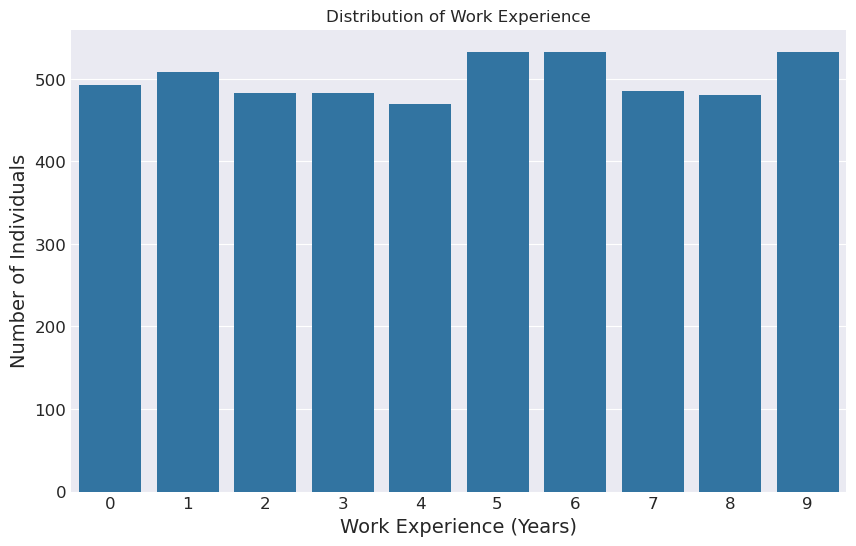

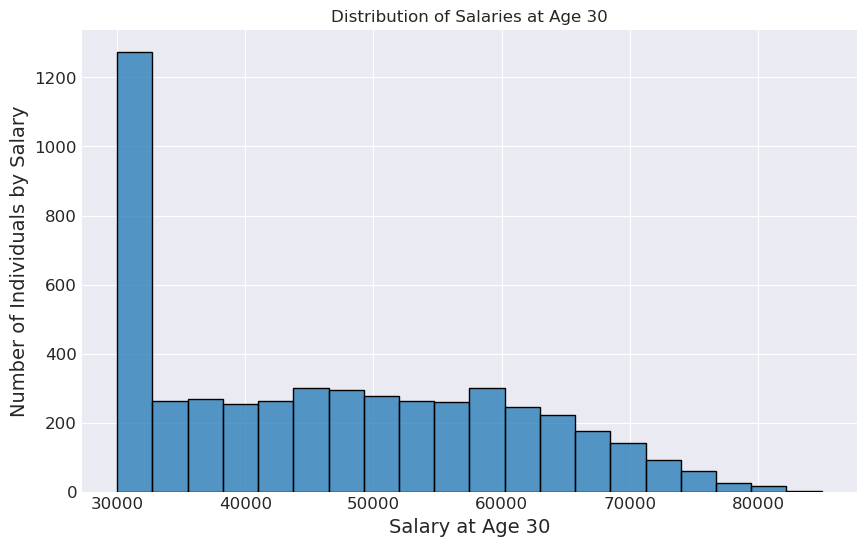

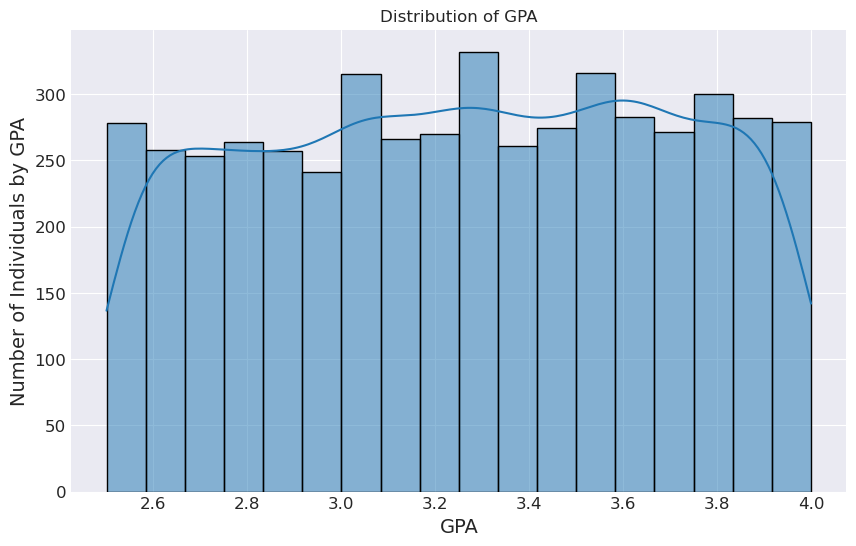

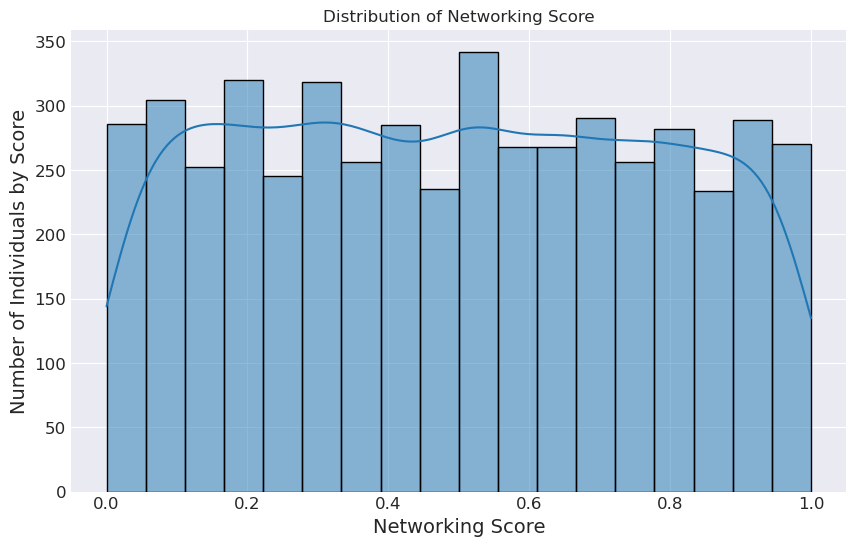

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

# Work Experience Distribution
sns.countplot(x='Work_Experience', data=df)
plt.xlabel('Work Experience (Years)')
plt.ylabel('Number of Individuals')
plt.title('Distribution of Work Experience')
plt.show()

# Salary Distribution
sns.histplot(df['Salary_at_30'], bins=20, kde=False)
plt.xlabel('Salary at Age 30')
plt.ylabel('Number of Individuals by Salary')
plt.title('Distribution of Salaries at Age 30')
plt.show()

# Visualize distribution of 'GPA'
sns.histplot(df['GPA'], kde=True)
plt.title('Distribution of GPA')
plt.xlabel('GPA')
plt.ylabel('Number of Individuals by GPA')
plt.show()

# Visualize distribution of 'Networking_Score'
sns.histplot(df['Networking_Score'], kde=True)
plt.title('Distribution of Networking Score')
plt.xlabel('Networking Score')
plt.ylabel('Number of Individuals by Score')
plt.show()




### Correlations Between Features

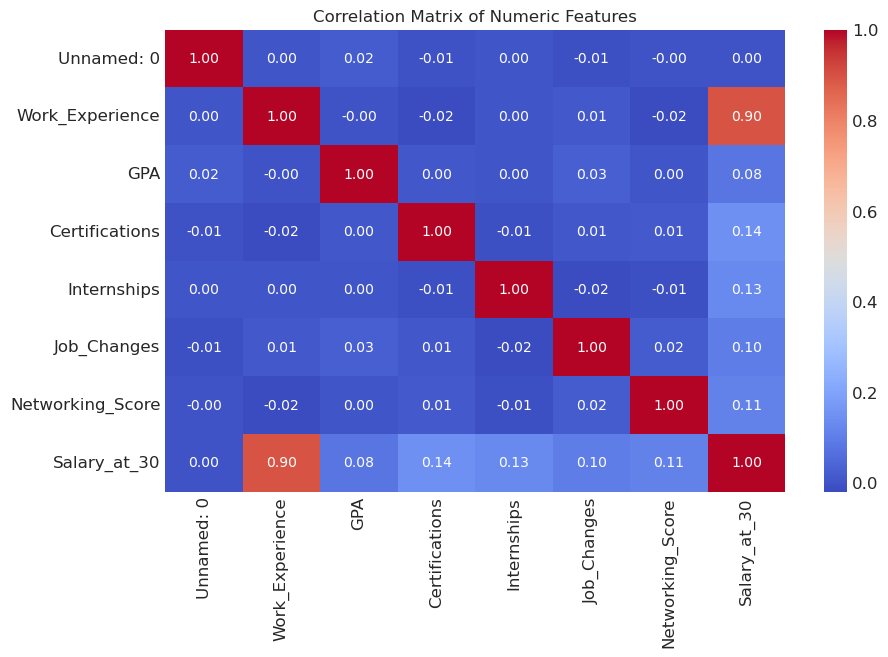

In [49]:
# Keep only numeric columns for correlation matrix
numeric_df = df.select_dtypes(include=['number'])

# Compute the correlation matrix
corr_matrix = numeric_df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numeric Features')
plt.show()


3.4: Categorical Feature Analysis (Bar Plots)

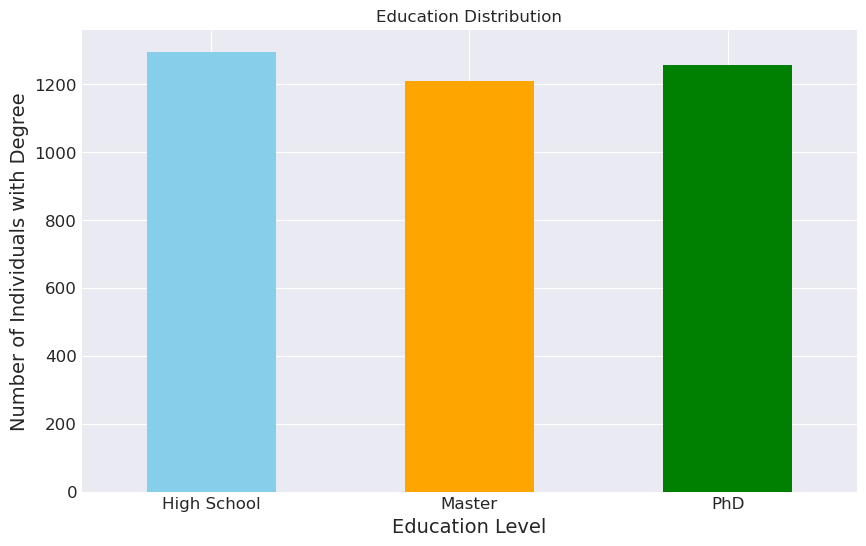

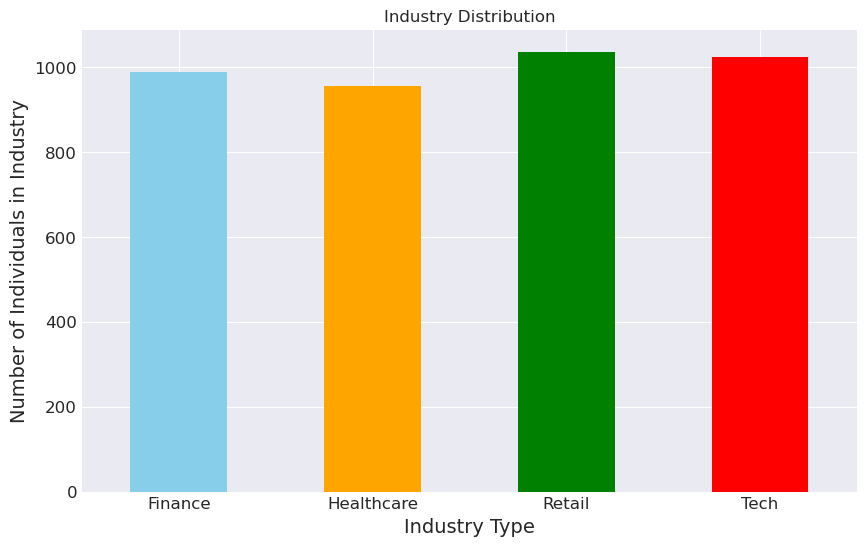

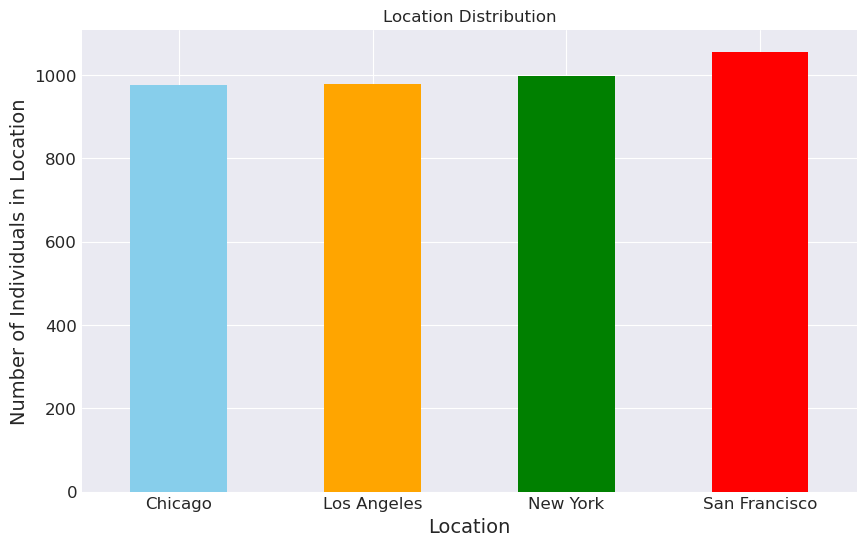

In [50]:
import matplotlib.pyplot as plt

# Education Distribution
education_columns = ['Education_High School', 'Education_Master', 'Education_PhD']
df[education_columns].sum().plot(kind='bar', color=['skyblue', 'orange', 'green'])
plt.title('Education Distribution')
plt.xlabel('Education Level')
plt.ylabel('Number of Individuals with Degree')
plt.xticks(ticks=range(len(education_columns)), labels=['High School', 'Master', 'PhD'], rotation=0)
plt.show()

# Industry Distribution
industry_columns = ['Industry_Finance', 'Industry_Healthcare', 'Industry_Retail', 'Industry_Tech']
df[industry_columns].sum().plot(kind='bar', color=['skyblue', 'orange', 'green', 'red'])
plt.title('Industry Distribution')
plt.xlabel('Industry Type')
plt.ylabel('Number of Individuals in Industry')
plt.xticks(ticks=range(len(industry_columns)), labels=['Finance', 'Healthcare', 'Retail', 'Tech'], rotation=0)
plt.show()

# Location Distribution
location_columns = ['Location_Chicago', 'Location_Los Angeles', 'Location_New York', 'Location_San Francisco']
df[location_columns].sum().plot(kind='bar', color=['skyblue', 'orange', 'green', 'red'])
plt.title('Location Distribution')
plt.xlabel('Location')
plt.ylabel('Number of Individuals in Location')
plt.xticks(ticks=range(len(location_columns)), labels=['Chicago', 'Los Angeles', 'New York', 'San Francisco'], rotation=0)
plt.show()



Pairwise Relationships (Scatter Plots)

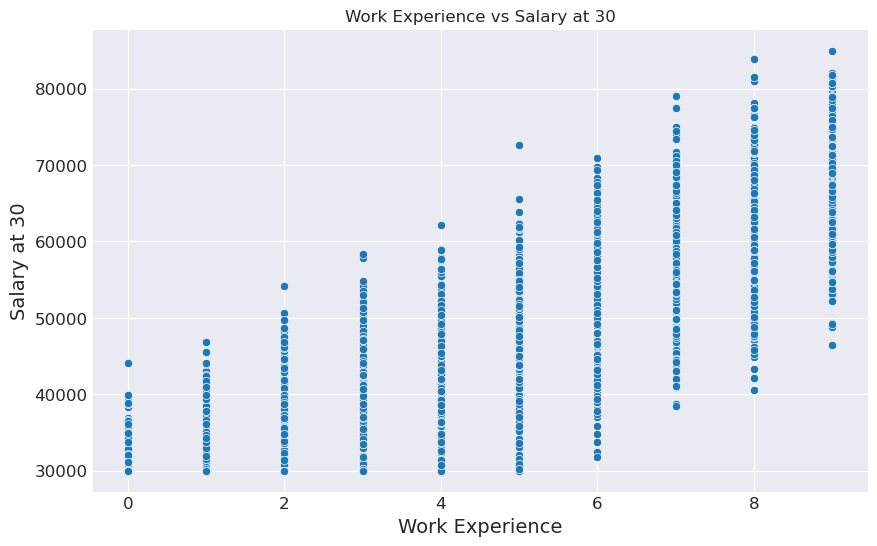

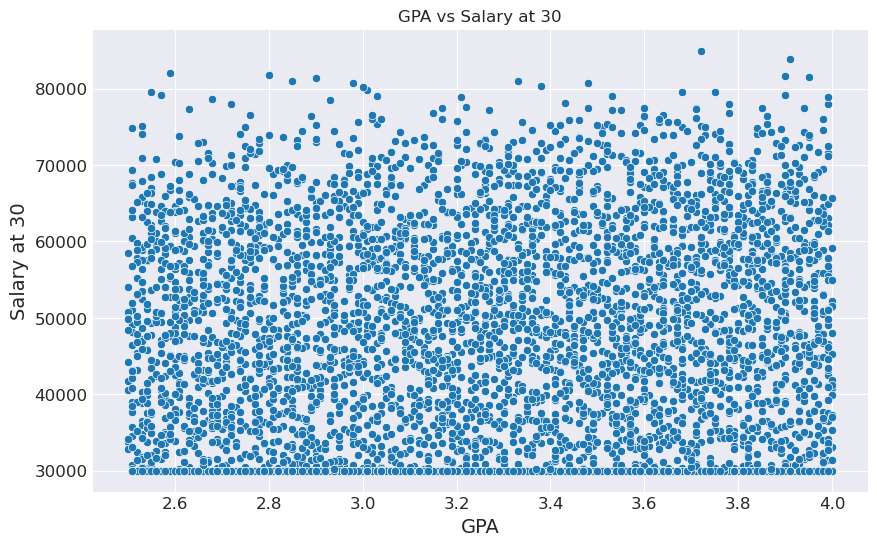

In [51]:
# Scatter plot for Work Experience vs Salary at 30
sns.scatterplot(x=df['Work_Experience'], y=df['Salary_at_30'])
plt.title('Work Experience vs Salary at 30')
plt.xlabel('Work Experience')
plt.ylabel('Salary at 30')
plt.show()

# Scatter plot for GPA vs Salary at 30
sns.scatterplot(x=df['GPA'], y=df['Salary_at_30'])
plt.title('GPA vs Salary at 30')
plt.xlabel('GPA')
plt.ylabel('Salary at 30')
plt.show()
